Figure 1 -- Three scenarios, p = 0.3
Scenario                      Peak PI     Month    Final PI    Final PV
----------------------------------------------------------------------
No control                     0.3707      60.0      0.3707      0.0000
Roguing only                   0.0936      60.0      0.0936      0.0757
Roguing + Buffer               0.0668      60.0      0.0668      0.0881


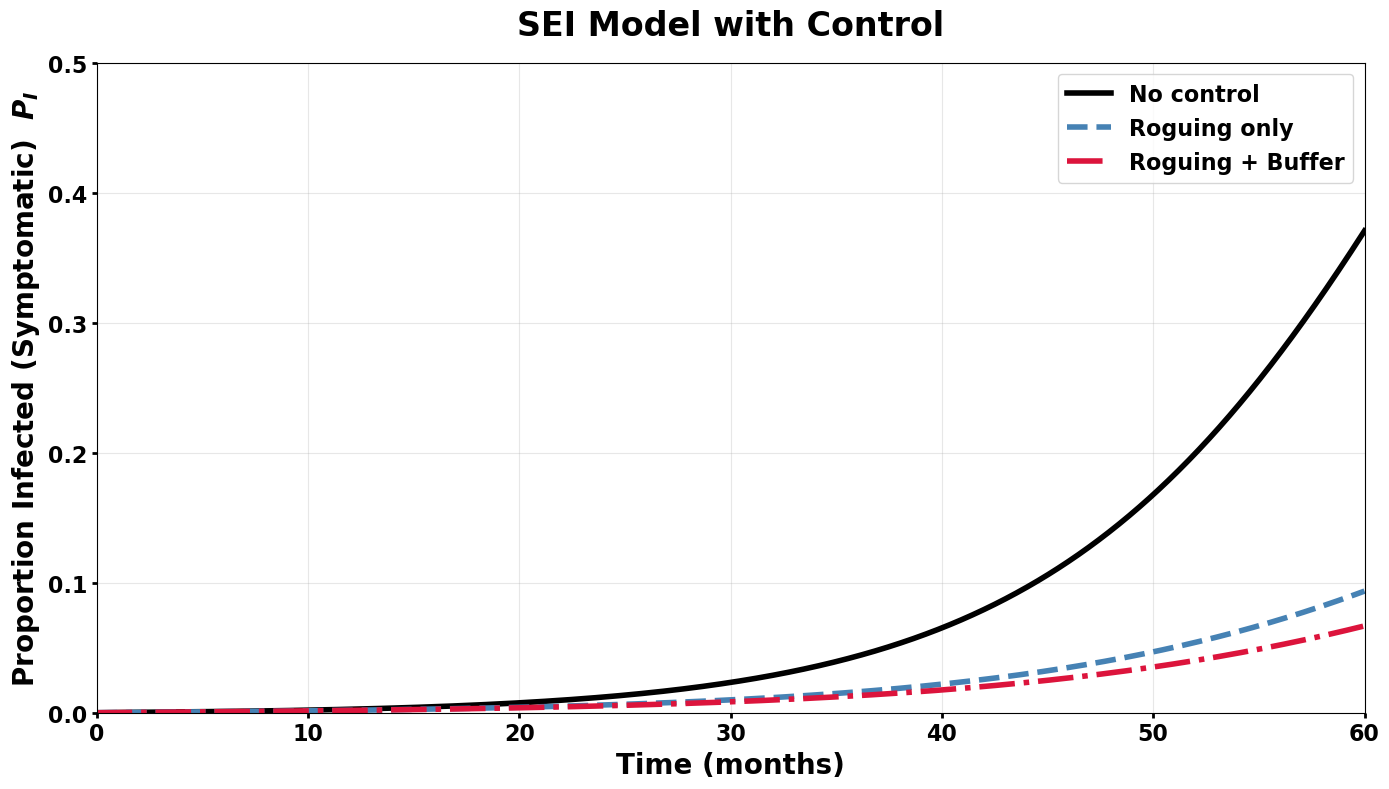


Figure 2 -- Varying p, roguing + buffer zone (r=c=0.2)
     p     Peak PI     Month    Final PI
----------------------------------------
   1.0      0.0031      60.0      0.0031
   0.7      0.0098      60.0      0.0098
   0.5      0.0243      60.0      0.0243
   0.3      0.0668      60.0      0.0668
   0.1      0.2044      60.0      0.2044


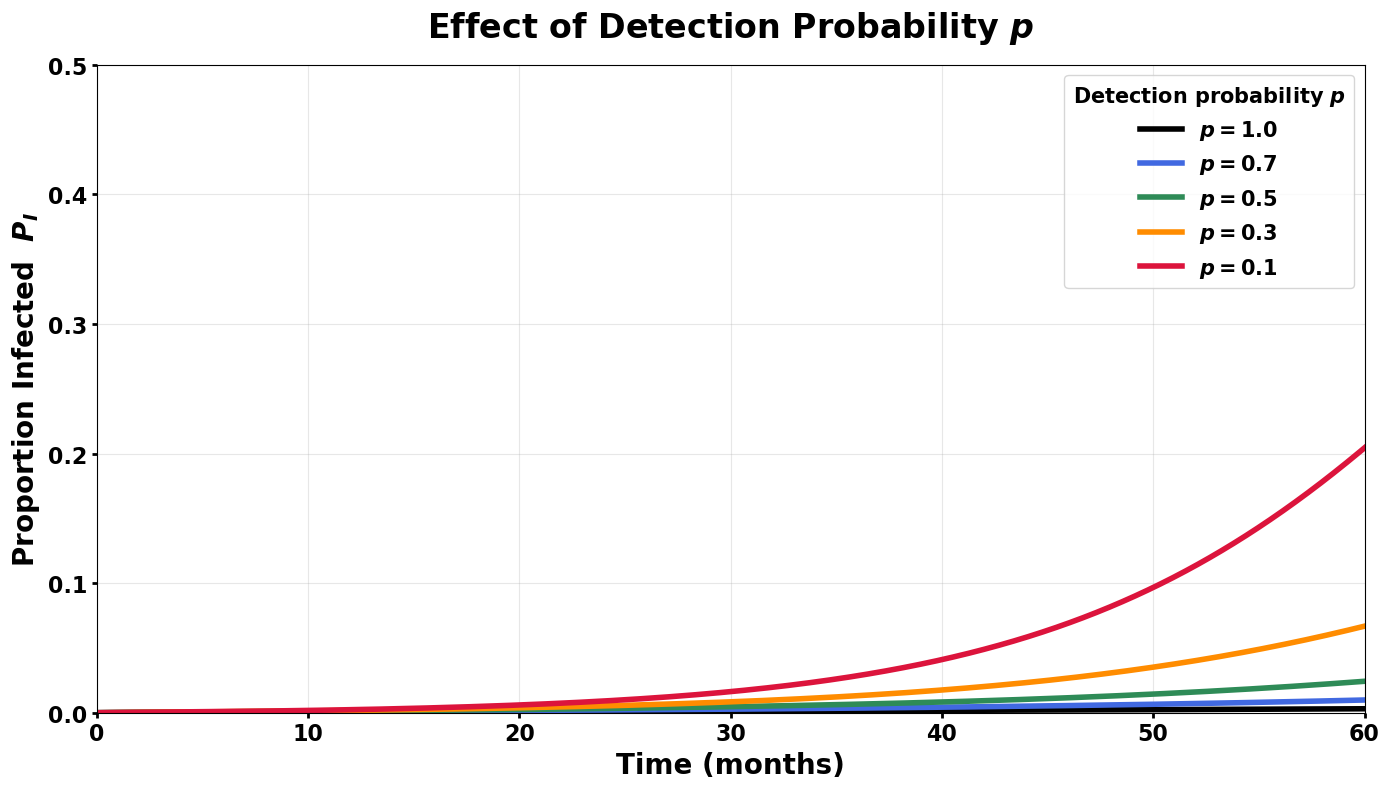


Conservation check (no control scenario):
  Max deviation from 1: 2.22e-16


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


beta = 0.82          # transmission rate (per month)
rho  = 1.0 / 10.53  # progression rate E->I
L    = 0.99          # local-to-global ratio

# Lattice 
N_lattice = 625      # 25 x 25

# Time grid: 60 months = 5 years
t_start = 0
t_end   = 60
t_eval  = np.linspace(t_start, t_end, 2000)

# Initial conditions
PE_init  = 1.0 / N_lattice
PS_init  = 1.0 - PE_init
PI_init  = 0.0
PSS_init = PS_init * PS_init
PSE_init = PS_init * PE_init
PSI_init = 0.0
PEE_init = PE_init * PE_init
PEI_init = 0.0
PII_init = 0.0

y0 = [PS_init, PE_init, PI_init,
      PSS_init, PSE_init, PSI_init,
      PEE_init, PEI_init, PII_init]


# ── The corrected SEI + Control ODE system ────────────────────
def sei_control_v2(t, y, beta, rho, L, r, c, p):
    
    PS, PE, PI, PSS, PSE, PSI, PEE, PEI, PII = y

    # Recover PV from singlet constraint
    PV = 1.0 - PS - PE - PI

    # Guard against division by zero
    if PS < 1e-12:
        qIS = 0.0
    else:
        qIS = PSI / PS    

    if PE < 1e-12:
        qIE = 0.0
    else:
        qIE = PEI / PE    

    # Effective control rates 
    pr = p * r    # effective roguing rate
    pc = p * c    # effective buffer zone rate

    # Infection pressure terms
    inf_S  = (1.0 - L) * PI + L * qIS
    inf_SS = (1.0 - L) * PI + (3.0/4.0) * L * qIS
    inf_SI = (1.0 - L) * PI + (1.0/4.0)*L + (3.0/4.0)*L*qIS

    # SINGLET EQUATIONS 
    
    dPS = -beta * PS * inf_S - pc * PSI

    dPE =  beta * PS * inf_S - rho * PE - pc * PEI

    dPI =  rho * PE - pr * PI

    # PAIR EQUATIONS
   
    dPSS = (-2.0 * beta * PSS * inf_SS
            -2.0 * pc   * PSS * qIS)

    dPSE = ( beta * PSS * inf_SS
            -beta * PSE * inf_SS
            -rho  * PSE
            -pc   * PSE * qIS
            -pc   * PEI * qIE)

    dPSI = ( rho  * PSE
            -beta * PSI * inf_SI
            -pr   * PSI
            -pc   * PSI * ((1.0/4.0) + (3.0/4.0)*qIS))

    dPEE = ( 2.0 * beta * PSE * inf_SS
            -2.0 * rho  * PEE
            -2.0 * pc   * PEE * qIE)

    dPEI = ( rho  * PEE
            +beta * PSI * inf_SI
            -rho  * PEI
            -pr   * PEI
            -pc   * PEI * ((1.0/4.0) + (3.0/4.0)*qIE))

    dPII = ( 2.0 * rho * PEI
            -2.0 * pr  * PII)

    return [dPS, dPE, dPI, dPSS, dPSE, dPSI, dPEE, dPEI, dPII]



scenarios = {
    'No control'          : {'r': 0.00, 'c': 0.00,
                              'color': 'black',     'ls': '-'},
    'Roguing only'        : {'r': 0.20, 'c': 0.00,
                              'color': 'steelblue', 'ls': '--'},
    'Roguing + Buffer'    : {'r': 0.20, 'c': 0.20,
                              'color': 'crimson',   'ls': '-.'},
}

# Detection probability
p_val = 0.3   # 30% of infected trees detected 


# =========================
# GLOBAL FONT SETTINGS
# =========================
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'


# FIGURE 1 -- PI under three scenarios, p=0.3
fig1, ax1 = plt.subplots(figsize=(14, 8))

print("Figure 1 -- Three scenarios, p = 0.3")
print(f"{'Scenario':25}  {'Peak PI':>10}  {'Month':>8}  "
      f"{'Final PI':>10}  {'Final PV':>10}")
print("-" * 70)

for name, params in scenarios.items():

    sol = solve_ivp(
        sei_control_v2,
        [t_start, t_end],
        y0,
        args=(beta, rho, L, params['r'], params['c'], p_val),
        t_eval=t_eval,
        method='Radau',
        rtol=1e-8,
        atol=1e-10
    )

    PS_s = sol.y[0]
    PE_s = sol.y[1]
    PI_s = sol.y[2]
    PV_s = 1.0 - PS_s - PE_s - PI_s

    ax1.plot(
        sol.t,
        PI_s,
        color=params['color'],
        linestyle=params['ls'],
        linewidth=4,
        label=name
    )

    print(f"{name:25}  {PI_s.max():>10.4f}  "
          f"{sol.t[PI_s.argmax()]:>8.1f}  "
          f"{PI_s[-1]:>10.4f}  {PV_s[-1]:>10.4f}")

ax1.set_title(
    'SEI Model with Control',
    fontsize=24,
    fontweight='bold',
    pad=20
)

ax1.set_xlabel(
    'Time (months)',
    fontsize=20,
    fontweight='bold'
)

ax1.set_ylabel(
    'Proportion Infected (Symptomatic)  $P_I$',
    fontsize=20,
    fontweight='bold'
)

ax1.set_xlim([0, t_end])
ax1.set_ylim([0, 0.5])

ax1.legend(fontsize=16)

ax1.grid(True, alpha=0.3)

ax1.tick_params(
    axis='both',
    labelsize=16,
    width=2
)

plt.tight_layout()

plt.savefig(
    'SEI_control_scenarios.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()



# FIGURE 2 -- Effect of detection probability p
# Roguing + Buffer zone combined, varying p

p_values  = [1.0, 0.7, 0.5, 0.3, 0.1]

colours_p = {
    1.0: 'black',
    0.7: 'royalblue',
    0.5: 'seagreen',
    0.3: 'darkorange',
    0.1: 'crimson'
}

fig2, ax2 = plt.subplots(figsize=(14, 8))

print("\nFigure 2 -- Varying p, roguing + buffer zone (r=c=0.2)")
print(f"{'p':>6}  {'Peak PI':>10}  {'Month':>8}  {'Final PI':>10}")
print("-" * 40)

for pv in p_values:

    sol = solve_ivp(
        sei_control_v2,
        [t_start, t_end],
        y0,
        args=(beta, rho, L, 0.2, 0.2, pv),
        t_eval=t_eval,
        method='Radau',
        rtol=1e-8,
        atol=1e-10
    )

    PI_s = sol.y[2]

    ax2.plot(
        sol.t,
        PI_s,
        color=colours_p[pv],
        linewidth=4,
        label=f'$p = {pv}$'
    )

    print(f"{pv:>6.1f}  {PI_s.max():>10.4f}  "
          f"{sol.t[PI_s.argmax()]:>8.1f}  {PI_s[-1]:>10.4f}")

ax2.set_title(
    'Effect of Detection Probability $p$',
    fontsize=24,
    fontweight='bold',
    pad=20
)

ax2.set_xlabel(
    'Time (months)',
    fontsize=20,
    fontweight='bold'
)

ax2.set_ylabel(
    'Proportion Infected  $P_I$',
    fontsize=20,
    fontweight='bold'
)

ax2.set_xlim([0, t_end])
ax2.set_ylim([0, 0.5])

ax2.legend(
    fontsize=15,
    title='Detection probability $p$',
    title_fontsize=15
)

ax2.grid(True, alpha=0.3)

ax2.tick_params(
    axis='both',
    labelsize=16,
    width=2
)

plt.tight_layout()

plt.savefig(
    'SEI_detection_probability.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


print("\nConservation check (no control scenario):")

sol_check = solve_ivp(
    sei_control_v2,
    [t_start, t_end],
    y0,
    args=(beta, rho, L, 0.0, 0.0, 0.3),
    t_eval=t_eval,
    method='Radau',
    rtol=1e-8,
    atol=1e-10
)

total = (
    sol_check.y[0]
    + sol_check.y[1]
    + sol_check.y[2]
    + (1 - sol_check.y[0] - sol_check.y[1] - sol_check.y[2])
)

print(f"  Max deviation from 1: "
      f"{np.max(np.abs(total - 1)):.2e}")